## Build a Basic Chatbot with Langgraph(Graph API)

In [1]:
from typing import Annotated

from typing_extensions import TypedDict

from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages  # These are called as Reducers

'''Hume baar baar input dena pdega to hum kya krenge ki hum input 
ko ek state me store kr denge aur fir usko use kr lenge and use me 
append kar denge using add_message function.'''

'Hume baar baar input dena pdega to hum kya krenge ki hum input \nko ek state me store kr denge aur fir usko use kr lenge and use me \nappend kar denge using add_message function.'

In [2]:
class State(TypedDict):
    # Messages have the type "list". The `add_messages` function
    # in the annotation defines how this state key should be updated
    # (in this case, it appends messages to the list, rather than overwriting them)
    messages:Annotated[list,add_messages]

graph_builder = StateGraph(State)

'''Reducer is not going to update the messages in the list instead it will append the messages in the list.'''

'Reducer is not going to update the messages in the list instead it will append the messages in the list.'

In [3]:
graph_builder

In [4]:
import os 
from dotenv import load_dotenv
load_dotenv()  # Load environment variables from .env file


True

In [5]:
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model

llm=ChatGroq(model="openai/gpt-oss-20b")

In [6]:
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.9', 'langchain': '1.4.4'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001E17AB4F380>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001E17AB4FE00>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [7]:
# Node functionality is defined in the function below.
# The function takes a state as input and returns a dictionary with the updated messages. 
# The `llm.invoke` method is called to generate a response based on the current messages in the state.

def chatbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}

In [8]:
graph_builder=StateGraph(State)

## Add the chatbot node to the graph and connect it to the start and end nodes.
graph_builder.add_node("llmchatbot",chatbot)

## Add edges to the graph to define the flow of execution. 
# The first edge connects the start node to the chatbot node, and the second edge connects the chatbot node to the end node.
graph_builder.add_edge(START,"llmchatbot")
graph_builder.add_edge("llmchatbot",END)

##` Compile the graph to create a runnable instance of the chatbot.`
graph=graph_builder.compile()

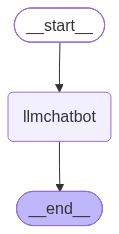

In [9]:
## Can we see how the graphs look like? Yes, we can visualize the graph using the `graph.visualize()` method. This will generate a visual representation of the graph, showing the nodes and edges that define the flow of execution.

from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

In [10]:
response=graph.invoke({"messages": "Hi"})

In [11]:
response["messages"][-1].content

'Hello! 👋 How can I help you today?'

In [12]:
# It is possible to stream the output of the chatbot in real-time using the `graph.stream()` method.
# This allows us to see the chatbot's responses as they are generated, rather than waiting for the entire 
# response to be completed before displaying it.

for event in graph.stream({"messages": "Hi,how are you?"}):
    for value in event.values():
        print(value["messages"][-1].content)

Hello! I'm doing great—thanks for asking. How can I help you today?


# ChatBot With Tools

In [13]:
from langchain_tavily import TavilySearch

tool=TavilySearch(max_results=2)
tool.invoke("What is langgraph?")

{'query': 'What is langgraph?',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.geeksforgeeks.org/machine-learning/what-is-langgraph',
   'title': 'What is LangGraph - GeeksforGeeks',
   'content': 'LangGraph is an open-source framework from LangChain designed to build and manage AI agent workflows using graph-based structures. It allows developers to define workflows as nodes and edges, making complex agent interactions more structured, scalable and easier to control. [...] langgraph: Framework for building graph-based AI workflows.\n langchain: Popular toolkit for LLM-powered AI applications.\n google-generativeai: Google’s API for Generative AI (Gemini models).\n\n Python  ````\n! pip install langgraph langchain google - generativeai\n```` \n\n### Step 2: Setup Gemini API [...] ## Building a Simple Chatbot with LangGraph\n\nLangGraph makes it easy to build structured, stateful applications like chatbots. In this example we’ll learn how

In [32]:
## custom function to use the tavily search tool and return the results in a dictionary format.

def multiply(a:int,b:int):
    """Munltiplyy a and b

    args:
        a (int): first number
        b (int): second number
    returns:
        int:output int
    """
    return {"result":a*b}

In [33]:
tools=[tool,multiply]

In [34]:
# Bind the tools to the LLM using the `bind_tools` method. This allows the LLM to use the tools when generating responses.
llm_with_tool=llm.bind_tools(tools)

In [35]:
llm_with_tool

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.9', 'langchain': '1.4.4'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001E17AB4F380>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001E17AB4FE00>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, and 

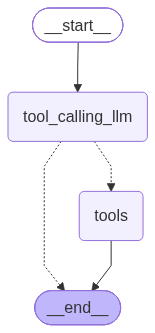

In [36]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Graph
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))


## Add edges to the graph to define the flow of execution.
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # The `tools_condition` function is used to determine which edge to follow based on the output of the `tool_calling_llm` node.
    # If the output indicates that a tool should be used, the edge to the "tools" node is followed. Otherwise, the edge to the END node is followed.
    tools_condition
)
builder.add_edge("tools",END)

## Compile the graph
graph=builder.compile()


## Display the graph
display(Image(graph.get_graph().draw_mermaid_png()))

In [25]:
response=graph.invoke({"messages":"What is the recent ai news?"})

In [26]:
response["messages"][-1].content

'{"query": "recent AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://blog.google/innovation-and-ai/technology/ai/google-ai-updates-september-2026", "title": "The latest AI news we announced in September 2026", "content": "Speed 0.75X 1X 1.5X 2X\\n\\n Read AI-generated summary \\n\\n   Check out the latest AI news from September 2026 in our monthly roundup.\\n   Gemini 4 Argon leads our new frontier models with advanced reasoning for complex tasks.\\n   We’ve launched natural voice models and new app integrations to simplify your daily workflow.\\n   Exciting scientific breakthroughs include mapping human DNA and tracking global methane from space.\\n   New tools like Googlebook and Gemini for Windows help you get more done effortlessly.\\n\\n Summaries were generated by Google AI. Generative AI is experimental. [...] September\'s headline belongs to Gemini 4 Argon, our newest frontier model. Built with advanced reasoning and a 1-million-t

In [28]:
## for displaying the output in streaming mode

for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

What is the recent ai news?
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_e4bbac3e-3c7b-4d27-9f1c-e0c1d04a26a7)
 Call ID: fc_e4bbac3e-3c7b-4d27-9f1c-e0c1d04a26a7
  Args:
    query: recent AI news
    search_depth: advanced
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://blog.google/innovation-and-ai/technology/ai/google-ai-updates-september-2026", "title": "The latest AI news we announced in September 2026", "content": "Speed 0.75X 1X 1.5X 2X\n\n Read AI-generated summary \n\n   Check out the latest AI news from September 2026 in our monthly roundup.\n   Gemini 4 Argon leads our new frontier models with advanced reasoning for complex tasks.\n   We’ve launch

In [37]:
'''tool call ho rha hai and topic show kr rha hai'''

response=graph.invoke({"messages":"What is 2*3?"})

for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

What is 2*3?
================================== Ai Message ==================================
Tool Calls:
  multiply (fc_f35b6f2b-10f7-4a7f-bf5d-6110f91ce739)
 Call ID: fc_f35b6f2b-10f7-4a7f-bf5d-6110f91ce739
  Args:
    a: 2
    b: 3
================================= Tool Message =================================
Name: multiply

{"result": 6}


In [38]:

response=graph.invoke({"messages":"Give me the recent ai news and also multiply 2*3."})

for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and also multiply 2*3.
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_1cd4450d-f236-40d8-a3af-687c963351c9)
 Call ID: fc_1cd4450d-f236-40d8-a3af-687c963351c9
  Args:
    query: latest AI news 2026
    search_depth: advanced
    time_range: week
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.fastcompany.com/91609818/applied-ai-next-big-things-in-tech-2026", "title": "The 13 next big things in applied AI for 2026", "content": "In April 2026, DeepL unveiled real-time voice-to-voice translation as part of its DeepL Voice translation product. A user can now speak naturally in their own language, while another user immediately 

''' Abhi ye seen hai 2 way hai ek way hai jo tool se End ho rha hai 
and dusra way hai jo direct end pe ja rha hai without using the tool.
what if we want to use tool but us tool pe loop rhe jo tool se o/p aayega
wo firse llm me he jaaye to uske liye hum kya krenge ki hum tool ke output 
ko firse llm me bhej denge and usko process kr lenge.This can be done using
a function called as REACT. 
'''

# So here the LLM has to take the decision what to do with the output it should directly process it or send it to the end This is where the AGENT comes in

# ReACT AGENT Architecture

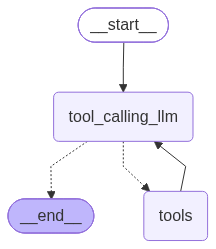

In [39]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

## compile the graph
graph=builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [42]:
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_2a6e32af-3513-43ed-90da-45a66b188707)
 Call ID: fc_2a6e32af-3513-43ed-90da-45a66b188707
  Args:
    query: recent AI news 2026 October
    search_depth: basic
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news 2026 October", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://martech.org/the-latest-ai-powered-martech-news-and-releases", "title": "The latest AI-powered martech news and releases", "content": "## October 1, 2026\n\n10Fold launched MetricsMatter 5.0, an expanded communications intelligence platform that turns media, social, digital, and AI visibility data into B2B business intelligence. It measures medi

# Adding Memory In Agentic Graph

Langgraph has a feature where in you can create a memory checkpointer

In [44]:
response=graph.invoke({"messages":"Hello, my name is Rishabh"})
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

Hello, my name is Rishabh
================================== Ai Message ==================================

Hello Rishabh! 👋 How can I help you today?


In [45]:
response=graph.invoke({"messages":"What is my name?"})
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

What is my name?
================================== Ai Message ==================================

I don’t have that information. If you’d like to tell me your name, I’ll remember it for this conversation!


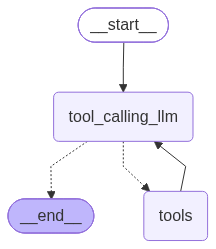

In [48]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.checkpoint.memory import InMemorySaver


# InMemorySaver is used to store the state of the graph in memory. This allows us to save the current state of the graph and resume from that point later, rather than starting from scratch each time.
memory=InMemorySaver()

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

## compile the graph
graph=builder.compile(checkpointer=memory)

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [49]:
config={"configurable":{"thread_id":"1"}}

response=graph.invoke({"messages":"Hello, my name is Rishabh"},config=config)
response

{'messages': [HumanMessage(content='Hello, my name is Rishabh', additional_kwargs={}, response_metadata={}, id='86148dc4-2fb2-4274-ba51-5ef2c5ce6149'),
  AIMessage(content='Nice to meet you, Rishabh! How can I help you today?', additional_kwargs={'reasoning_content': 'User says "Hello, my name is Rishabh". Probably wants a friendly response. No tool needed.'}, response_metadata={'token_usage': {'completion_tokens': 48, 'prompt_tokens': 375, 'total_tokens': 423, 'completion_time': 0.049917442, 'completion_tokens_details': {'reasoning_tokens': 23}, 'prompt_time': 0.098929859, 'prompt_tokens_details': {'cached_tokens': 256}, 'queue_time': 0.209099918, 'total_time': 0.148847301}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_a8c584dda7', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a121de-342d-7291-8111-5742535ce60b-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 375, 'output_token

In [50]:
response["messages"][-1].content

'Nice to meet you, Rishabh! How can I help you today?'

In [52]:
response=graph.invoke({"messages":"What is my name?"},config=config)
response["messages"][-1].content

'Your name is Rishabh.'

## Streaming

In [54]:
def superbot(state:State):
    return {"messages":[llm.invoke(state['messages'])]}

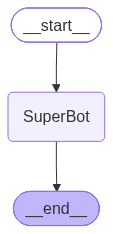

In [55]:
graph=StateGraph(State)

## node
graph.add_node("SuperBot",superbot)
## Edges

graph.add_edge(START,"SuperBot")
graph.add_edge("SuperBot",END)


graph_builder=graph.compile(checkpointer=memory)


## Display
from IPython.display import Image, display
display(Image(graph_builder.get_graph().draw_mermaid_png()))

In [56]:
''' Streaming is used to display the output of the graph in real-time 
as it is being generated. This allows us to see the chatbot's responses
as they are generated, rather than waiting for the entire response to be 
completed before displaying it.
'''

" Streaming is used to display the output of the graph in real-time \nas it is being generated. This allows us to see the chatbot's responses\nas they are generated, rather than waiting for the entire response to be \ncompleted before displaying it.\n"

### Streaming 
Methods: .stream() and astream()

- These methods are sync and async methods for streaming back results.

Additional parameters in streaming modes for graph state

- **values** : This streams the full state of the graph after each node is called.
- **updates** : This streams updates to the state of the graph after each node is called.

In [ ]:
## Create a thread


In [58]:
# Create a thread
config = {"configurable": {"thread_id": "3"}}


## here mode=updates which means that the output will get updated
for chunk in graph_builder.stream({'messages':"Hi,My name is Krish And I like cricket"},config,stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content='Hello Krish! 👋🏼 It’s great to meet a cricket fan. How can I help you today? Are you looking for the latest scores, match schedules, player stats, or something else? Let me know!', additional_kwargs={'reasoning_content': "We need to respond. There's no specific instruction beyond the user greeting. Should greet and ask how to help. Probably ask if they want cricket info."}, response_metadata={'token_usage': {'completion_tokens': 85, 'prompt_tokens': 82, 'total_tokens': 167, 'completion_time': 0.08992294, 'completion_tokens_details': {'reasoning_tokens': 31}, 'prompt_time': 0.030584171, 'prompt_tokens_details': None, 'queue_time': 0.339937366, 'total_time': 0.120507111}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_34cb00738d', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a121e9-f7a8-7060-8d48-609f3b2cc1a2-0', tool_calls=[], invalid_tool_calls=[], usage_metad

In [59]:
## here mode is set to "values" which means that the output of the graph will be streamed as a series of values, rather than as a series of updates. This allows us to see the chatbot's responses as they are generated, rather than waiting for the entire response to be completed before displaying it.

for chunk in graph_builder.stream({'messages':"Hi,My name is Krish And I like cricket"},config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi,My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='509f3df8-0f57-4794-9392-2ed98a176f31'), AIMessage(content='Hello Krish! 👋🏼 It’s great to meet a cricket fan. How can I help you today? Are you looking for the latest scores, match schedules, player stats, or something else? Let me know!', additional_kwargs={'reasoning_content': "We need to respond. There's no specific instruction beyond the user greeting. Should greet and ask how to help. Probably ask if they want cricket info."}, response_metadata={'token_usage': {'completion_tokens': 85, 'prompt_tokens': 82, 'total_tokens': 167, 'completion_time': 0.08992294, 'completion_tokens_details': {'reasoning_tokens': 31}, 'prompt_time': 0.030584171, 'prompt_tokens_details': None, 'queue_time': 0.339937366, 'total_time': 0.120507111}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_34cb00738d', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs

In [63]:
# Create a thread
config = {"configurable": {"thread_id": "4"}}

for chunk in graph_builder.stream({'messages':"Hi,My name is Krish And I like cricket"},config,stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content='Hey Krish! 👋🏼\n\nNice to meet another cricket fan. Which team or league keeps you excited? And do you have a favorite player or a particular style of play you love watching? Let’s dive into the world of wickets and runs together!', additional_kwargs={'reasoning_content': 'User repeats: "Hi,My name is Krish And I like cricket". The user seems to want to interact. The system says: "You are ChatGPT, a large language model trained by OpenAI. Knowledge cutoff 2024-06." There\'s no policy violation. We can respond with a friendly greeting. The user might want to talk about cricket. So we respond.'}, response_metadata={'token_usage': {'completion_tokens': 139, 'prompt_tokens': 475, 'total_tokens': 614, 'completion_time': 0.163932389, 'completion_tokens_details': {'reasoning_tokens': 78}, 'prompt_time': 0.027459283, 'prompt_tokens_details': None, 'queue_time': 0.312927775, 'total_time': 0.191391672}, 'model_name': 'openai/gpt-oss-20b', 'system_fing

In [65]:
for chunk in graph_builder.stream({'messages':"I also like football"},config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi,My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='f6db1ed0-46e5-4db0-b7e2-3e19b92a91c5'), AIMessage(content='Hey Krish! 👋🏼\n\nNice to meet you—cricket fan, huh? That’s awesome! Are you into any particular team or league? Maybe the IPL, BBL, or the international circuit? And do you have a favorite player or a position you love watching (like batting, bowling, or all‑rounder action)? Let me know, and we can chat about the latest matches, stats, or even some classic moments that never get old!', additional_kwargs={'reasoning_content': 'We need to respond in a friendly tone. The user says "Hi, My name is Krish And I like cricket". We can greet them, ask about cricket, maybe ask what teams they like, what position, etc. Also we can mention we are ChatGPT. Let\'s keep it engaging.'}, response_metadata={'token_usage': {'completion_tokens': 165, 'prompt_tokens': 82, 'total_tokens': 247, 'completion_time': 0.174875005, '

In [66]:
config = {"configurable": {"thread_id": "5"}}

async for event in graph_builder.astream_events({"messages":["Hi My name is Krish and I like to play cricket"]},config,version="v2"):
    print(event)

{'event': 'on_chain_start', 'data': {'input': {'messages': ['Hi My name is Krish and I like to play cricket']}}, 'name': 'LangGraph', 'tags': [], 'run_id': '01a12952-9d33-7d61-9879-9c61fb94812e', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph'}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='Hi My name is Krish and I like to play cricket', additional_kwargs={}, response_metadata={}, id='8c955833-2dba-46f9-967c-f53b1a3b5ff6')]}}, 'name': 'SuperBot', 'tags': ['graph:step:1'], 'run_id': '01a12952-9d63-72e3-b5fa-45556ef7e49f', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph', 'langgraph_step': 1, 'langgraph_node': 'SuperBot', 'langgraph_triggers': ('branch:to:SuperBot',), 'langgraph_path': ('__pregel_pull', 'SuperBot'), 'langgraph_checkpoint_ns': 'SuperBot:cc2a5636-379f-6cab-c55b-209bf25cb556'}, 'parent_ids': ['01a12952-9d33-7d61-9879-9c61fb94812e']}
{'event': 'on_chat_model_start', 'data': {'input': {'messages':